# Flood-response SoS analysis across flood scenarios


In [43]:
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.cbook import boxplot_stats
from matplotlib.ticker import MaxNLocator

flood_order = ["slower_flood", "baseline_flood", "faster_flood"]
flood_labels = {
    "slower_flood": "Slower flood (0.5x)",
    "baseline_flood": "Baseline flood (1x)",
    "faster_flood": "Faster flood (2x)",
}

# Locate the prototype from its folder, a child folder, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
candidates += [path / "flood_sos" for path in list(candidates)]
candidates += [path / "prototype" / "flood_sos" for path in list(candidates)]
project_dir = next((path for path in candidates
                    if (path / "output" / "baseline_flood" / "simulation_runs.csv").exists()), None)
if project_dir is None:
    raise FileNotFoundError("Could not locate output/baseline_flood/simulation_runs.csv.")
output_dir = project_dir / "output"
required_files = ("simulation_runs.csv", "flood_history.csv", "simulation_summary.json")
missing_files = [str(output_dir / case / name)
                 for case in flood_order for name in required_files
                 if not (output_dir / case / name).is_file()]
if missing_files:
    raise FileNotFoundError("Missing flood-scenario outputs:\n" + "\n".join(missing_files))

def read_case_summary(case):
    with (output_dir / case / "simulation_summary.json").open(encoding="utf-8") as file:
        return json.load(file)

run_frames, history_frames, summaries = [], [], {}
for case in flood_order:
    run_frame = pd.read_csv(output_dir / case / "simulation_runs.csv")
    history_frame = pd.read_csv(output_dir / case / "flood_history.csv")
    run_frame["flood_case"] = case
    history_frame["flood_case"] = case
    run_frames.append(run_frame)
    history_frames.append(history_frame)
    # Keep only compact metadata/aggregates here. Load detailed traces one
    # case at a time in the transition cell to limit memory use.
    document = read_case_summary(case)
    summaries[case] = {"experiment": document["experiment"], "aggregates": document["aggregates"]}
    del document
runs_all = pd.concat(run_frames, ignore_index=True)
flood_all = pd.concat(history_frames, ignore_index=True)
del run_frames, history_frames, run_frame, history_frame

# Apply the same sensitivity filter independently to every flood scenario.
selected_rescue_sensitivity = "boat_emphasis"
for case in flood_order:
    available = set(runs_all.loc[runs_all["flood_case"] == case, "rescue_sensitivity"].dropna())
    if selected_rescue_sensitivity not in available:
        raise ValueError(f"{flood_labels[case]} has no {selected_rescue_sensitivity!r} runs; available: {sorted(available)}")
runs = runs_all.loc[runs_all["rescue_sensitivity"] == selected_rescue_sensitivity].copy()
flood = flood_all.loc[flood_all["rescue_sensitivity"] == selected_rescue_sensitivity].copy()

scenario_order = ["low_only", "high_only", "mixed"]
scenario_labels = {
    "low_only": "St. permissive",
    "high_only": "St. restrictive",
    "mixed": "Dynamic",
}
scenario_colors = {
    "low_only": "#777777",  # Preserve Static permissive's current color.
    "high_only": "darkorange",
    "mixed": "dodgerblue",
}
scenario_line_styles = {"low_only": "-", "high_only": "--", "mixed": "-."}
configuration_order = ["reduced_departure", "baseline", "increased_departure"]
configuration_labels = {
    "reduced_departure": "Low",
    "baseline": "Ref.",
    "increased_departure": "High",
}
configuration_markers = {
    "reduced_departure": "o",
    "baseline": "s",
    "increased_departure": "^",
}

# Match the reference notebook's compact, paper-oriented matplotlib style.
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def format_axis(ax):
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", pad=1.5)


# Export separately so the original notebook's figures are preserved.
plot_dir = project_dir / "plots" / "all_scenarios"
plot_dir.mkdir(parents=True, exist_ok=True)

def print_plot_values(title, values, scope=None):
    """Print exactly the plotted aggregates, including flood-scenario labels."""
    table = values.copy().rename(columns={
        "flood_case": "Flood scenario", "scenario": "Policy strategy",
        "profile_configuration": "Departure rate",
    })
    for column, mapping in (("Flood scenario", flood_labels),
                            ("Policy strategy", scenario_labels),
                            ("Departure rate", configuration_labels)):
        if column in table.columns:
            table[column] = table[column].map(lambda value: mapping.get(value, value))
    print(f"\n{title}\nSensitivity condition: {selected_rescue_sensitivity}")
    if scope:
        print(scope)
    print(table.to_string(index=False, max_rows=None, max_cols=None,
                          float_format=lambda value: f"{value:.6f}"))

strategy_handles = [Line2D([0], [0], color=scenario_colors[strategy],
                          linestyle=scenario_line_styles[strategy],
                          label=scenario_labels[strategy]) for strategy in scenario_order]
print("Flood scenarios (inflow in cubic metres per simulated minute):")
for case in flood_order:
    config = summaries[case]["experiment"]["simulation_config"]
    count = int((runs["flood_case"] == case).sum())
    print(f"  {flood_labels[case]}: {config['flood_inflow_m3_per_minute']:,.0f}; {count} runs")
print("Departure rates (requests per eligible constituent per simulated minute):")
for configuration in configuration_order:
    values = [summaries[case]["experiment"]["profile_configurations"][configuration]["Reactive"]["departure_rate"]
              for case in flood_order]
    if len(set(values)) != 1:
        raise ValueError(f"Departure-rate settings differ across flood scenarios: {configuration}")
    print(f"  {configuration_labels[configuration]}: {values[0]}")


Flood scenarios (inflow in cubic metres per simulated minute):
  Slower flood (0.5x): 1,750; 270 runs
  Baseline flood (1x): 3,500; 270 runs
  Faster flood (2x): 7,000; 270 runs
Departure rates (requests per eligible constituent per simulated minute):
  Low: 0.04
  Ref.: 0.08
  High: 0.16


## Mission objective achievement across runs


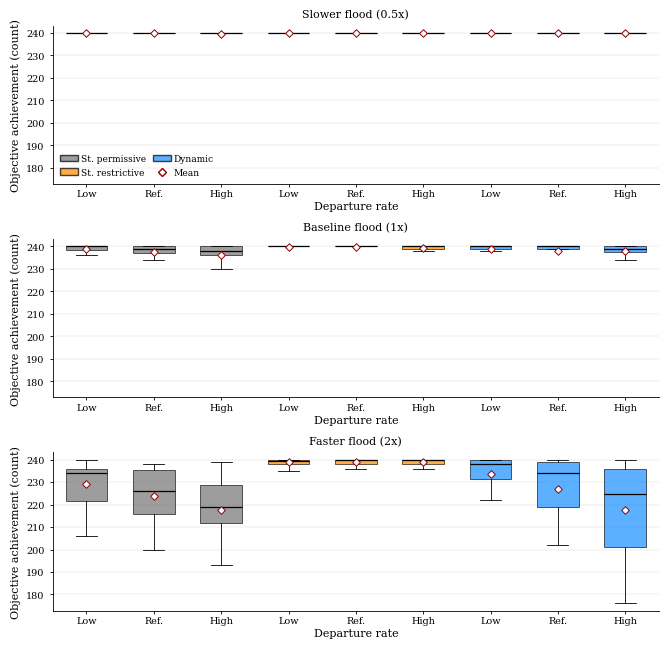


Mission objective achievement across runs
Sensitivity condition: boat_emphasis
Same 1.5-IQR whiskers and hidden outlier markers as the original plot; y-axis scale shared across flood scenarios.
     Flood scenario Policy strategy Departure rate  Runs  Mean achievement (count)  Median achievement (count)  Q1 (count)  Q3 (count)  Lower whisker (count)  Upper whisker (count)
Slower flood (0.5x)  St. permissive            Low    30                239.766667                  240.000000  240.000000  240.000000                    240                    240
Slower flood (0.5x)  St. permissive           Ref.    30                239.866667                  240.000000  240.000000  240.000000                    240                    240
Slower flood (0.5x)  St. permissive           High    30                239.700000                  240.000000  240.000000  240.000000                    240                    240
Slower flood (0.5x) St. restrictive            Low    30                240.00000

In [44]:
objective_column = "mission_objective_achievement"
objective_box_rows = []
fig, axes = plt.subplots(len(flood_order), 1, figsize=(6.6, 6.4), sharey=True)
for ax, case in zip(axes, flood_order):
    case_runs = runs.loc[runs["flood_case"] == case]
    condition_order = [(strategy, configuration)
                       for strategy in scenario_order for configuration in configuration_order
                       if ((case_runs["scenario"] == strategy)
                           & (case_runs["profile_configuration"] == configuration)).any()]
    condition_values = [case_runs.loc[(case_runs["scenario"] == strategy)
                                    & (case_runs["profile_configuration"] == configuration),
                                    objective_column].dropna().to_numpy()
                        for strategy, configuration in condition_order]
    box = ax.boxplot(condition_values, patch_artist=True, showfliers=False, widths=0.62,
                     medianprops={"color": "black", "linewidth": 0.9},
                     whiskerprops={"color": "black", "linewidth": 0.6},
                     capprops={"color": "black", "linewidth": 0.6})
    for patch, (strategy, _) in zip(box["boxes"], condition_order):
        patch.set_facecolor(scenario_colors[strategy])
        patch.set_edgecolor("black")
        patch.set_linewidth(0.6)
        patch.set_alpha(0.72)
    means = [values.mean() for values in condition_values]
    ax.scatter(np.arange(1, len(means) + 1), means, marker="D", s=15,
               facecolor="white", edgecolor="darkred", linewidth=0.7, zorder=4)
    ax.set_xticks(np.arange(1, len(condition_order) + 1))
    ax.set_xticklabels([configuration_labels[configuration] for _, configuration in condition_order], fontsize=7)
    ax.set_xlabel("Departure rate", labelpad=2)
    ax.set_ylabel("Objective achievement (count)")
    ax.set_title(flood_labels[case])
    format_axis(ax)
    for (strategy, configuration), values in zip(condition_order, condition_values):
        stats = boxplot_stats(values, whis=1.5)[0]
        objective_box_rows.append({
            "flood_case": case, "scenario": strategy, "profile_configuration": configuration,
            "Runs": len(values), "Mean achievement (count)": stats["mean"],
            "Median achievement (count)": stats["med"], "Q1 (count)": stats["q1"],
            "Q3 (count)": stats["q3"], "Lower whisker (count)": stats["whislo"],
            "Upper whisker (count)": stats["whishi"],
        })
legend_handles = [Patch(facecolor=scenario_colors[strategy], edgecolor="black", alpha=0.72,
                        label=scenario_labels[strategy]) for strategy in scenario_order]
legend_handles.append(Line2D([0], [0], marker="D", color="darkred", markerfacecolor="white",
                             linestyle="None", markersize=4, label="Mean"))
axes[0].legend(handles=legend_handles, frameon=False, ncol=2, loc="lower left",
               fontsize=6.5, columnspacing=0.8, handletextpad=0.3, borderaxespad=0.4)
fig.tight_layout(pad=0.5, h_pad=1.0)
fig.savefig(plot_dir / "mission_objective_achievement_across_runs.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()
print_plot_values("Mission objective achievement across runs", pd.DataFrame(objective_box_rows),
                  "Same 1.5-IQR whiskers and hidden outlier markers as the original plot; y-axis scale shared across flood scenarios.")


## Flood trajectory


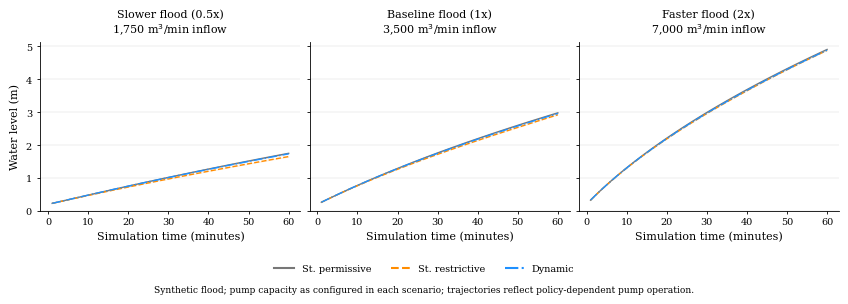


Flood trajectory
Sensitivity condition: boat_emphasis
Departure-rate conditions are pooled within each flood scenario, as in the original plot. Bands use mean +/- 1.96 * SD / sqrt(observations).
     Flood scenario Policy strategy  Simulation time (min)  Mean water level (m)  Water-level SD (m)  Observations  Lower plotted band (m)  Upper plotted band (m)
Baseline flood (1x) St. restrictive               1.000000              0.260000            0.000000            90                0.260000                0.260000
Baseline flood (1x) St. restrictive               2.000000              0.319111            0.000741            90                0.318958                0.319264
Baseline flood (1x) St. restrictive               3.000000              0.377389            0.001714            90                0.377035                0.377743
Baseline flood (1x) St. restrictive               4.000000              0.434744            0.002974            90                0.434130              

In [45]:
flood_stats = (flood.groupby(["flood_case", "scenario", "time_minutes"], observed=True)["water_level_m"]
               .agg(mean="mean", std="std", count="count").reset_index())
fig, axes = plt.subplots(1, len(flood_order), figsize=(8.4, 2.9), sharex=True, sharey=True)
for ax, case in zip(axes, flood_order):
    for strategy in scenario_order:
        part = flood_stats.loc[(flood_stats["flood_case"] == case)
                               & (flood_stats["scenario"] == strategy)].sort_values("time_minutes")
        if part.empty:
            continue
        band = 1.96 * part["std"].fillna(0) / np.sqrt(part["count"].clip(lower=1))
        ax.plot(part["time_minutes"], part["mean"], color=scenario_colors[strategy],
                linestyle=scenario_line_styles[strategy], linewidth=1.0, label=scenario_labels[strategy])
        ax.fill_between(part["time_minutes"], part["mean"] - band, part["mean"] + band,
                        color=scenario_colors[strategy], alpha=0.14, linewidth=0)
    config = summaries[case]["experiment"]["simulation_config"]
    inflow = config["flood_inflow_m3_per_minute"]
    ax.set_title(f"{flood_labels[case]}\n{inflow:,.0f} m$^3$/min inflow")
    ax.set_xlabel("Simulation time (minutes)")
    format_axis(ax)
axes[0].set_ylabel("Water level (m)")
fig.legend(handles=strategy_handles, frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 0.04))
fig.text(0.5, 0.005, "Synthetic flood; pump capacity as configured in each scenario; trajectories reflect policy-dependent pump operation.",
         ha="center", fontsize=6.5)
fig.tight_layout(rect=(0, 0.16, 1, 1), pad=0.5)
fig.savefig(plot_dir / "flood_trajectory.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()
flood_print = flood_stats.copy()
flood_band = 1.96 * flood_print["std"].fillna(0) / np.sqrt(flood_print["count"].clip(lower=1))
flood_print["Lower plotted band (m)"] = flood_print["mean"] - flood_band
flood_print["Upper plotted band (m)"] = flood_print["mean"] + flood_band
flood_print = flood_print.rename(columns={"time_minutes": "Simulation time (min)",
    "mean": "Mean water level (m)", "std": "Water-level SD (m)", "count": "Observations"})
print_plot_values("Flood trajectory", flood_print,
                  "Departure-rate conditions are pooled within each flood scenario, as in the original plot. Bands use mean +/- 1.96 * SD / sqrt(observations).")


## Mission objective achievement over time


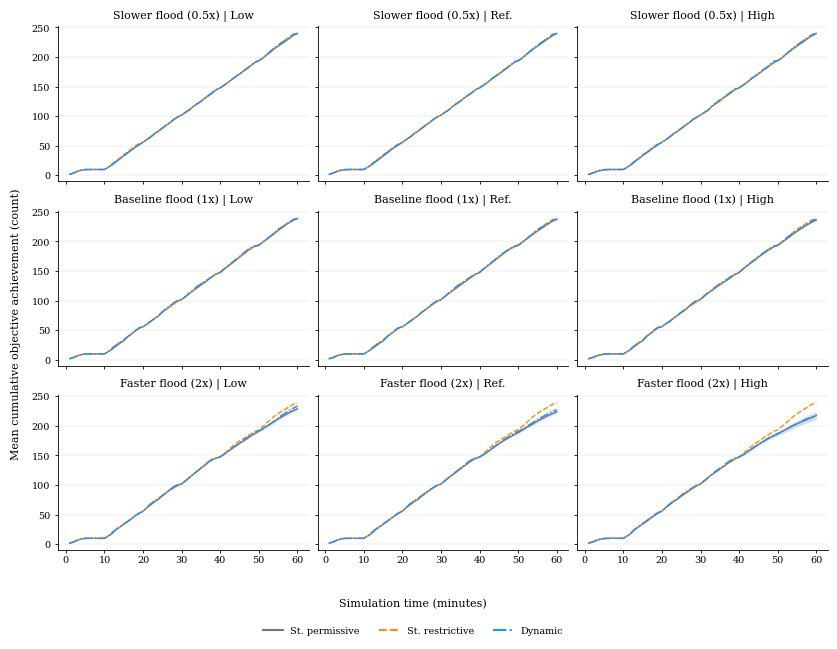


Mission objective achievement over time
Sensitivity condition: boat_emphasis
Flood scenarios and departure-rate conditions remain separate. Bands use mean +/- 1.96 * SD / sqrt(observations).
     Flood scenario Departure rate Policy strategy  Simulation time (min)  Mean cumulative objective achievement (count)  Objective-achievement SD (count)  Observations  Lower plotted band (count)  Upper plotted band (count)
Baseline flood (1x)           Ref. St. restrictive               1.000000                                       2.000000                          0.000000            30                    2.000000                    2.000000
Baseline flood (1x)           Ref. St. restrictive               2.000000                                       4.000000                          0.000000            30                    4.000000                    4.000000
Baseline flood (1x)           Ref. St. restrictive               3.000000                                       7.000000             

In [46]:
objective_stats = (flood.groupby(["flood_case", "profile_configuration", "scenario", "time_minutes"], observed=True)
                   ["mission_objective_achievement"].agg(mean="mean", std="std", count="count").reset_index())
fig, axes = plt.subplots(len(flood_order), len(configuration_order), figsize=(8.4, 6.4),
                         sharex=True, sharey=True, squeeze=False)
for row, case in enumerate(flood_order):
    for column, configuration in enumerate(configuration_order):
        ax = axes[row, column]
        for strategy in scenario_order:
            part = objective_stats.loc[(objective_stats["flood_case"] == case)
                & (objective_stats["profile_configuration"] == configuration)
                & (objective_stats["scenario"] == strategy)].sort_values("time_minutes")
            if part.empty:
                continue
            band = 1.96 * part["std"].fillna(0) / np.sqrt(part["count"].clip(lower=1))
            ax.plot(part["time_minutes"], part["mean"], color=scenario_colors[strategy],
                    linestyle=scenario_line_styles[strategy], linewidth=1.0, label=scenario_labels[strategy])
            ax.fill_between(part["time_minutes"], part["mean"] - band, part["mean"] + band,
                            color=scenario_colors[strategy], alpha=0.14, linewidth=0)
        ax.set_title(f"{flood_labels[case]} | {configuration_labels[configuration]}")
        format_axis(ax)
fig.supylabel("Mean cumulative objective achievement (count)", fontsize=8)
fig.supxlabel("Simulation time (minutes)", y=0.055, fontsize=8)
fig.legend(handles=strategy_handles, frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0.02, 0.09, 1, 1), pad=0.5, h_pad=0.8)
fig.savefig(plot_dir / "mission_objective_achievement_over_time.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()
objective_print = objective_stats.copy()
objective_band = 1.96 * objective_print["std"].fillna(0) / np.sqrt(objective_print["count"].clip(lower=1))
objective_print["Lower plotted band (count)"] = objective_print["mean"] - objective_band
objective_print["Upper plotted band (count)"] = objective_print["mean"] + objective_band
objective_print = objective_print.rename(columns={"time_minutes": "Simulation time (min)",
    "mean": "Mean cumulative objective achievement (count)",
    "std": "Objective-achievement SD (count)", "count": "Observations"})
print_plot_values("Mission objective achievement over time", objective_print,
                  "Flood scenarios and departure-rate conditions remain separate. Bands use mean +/- 1.96 * SD / sqrt(observations).")


## Mission success versus mean base cost


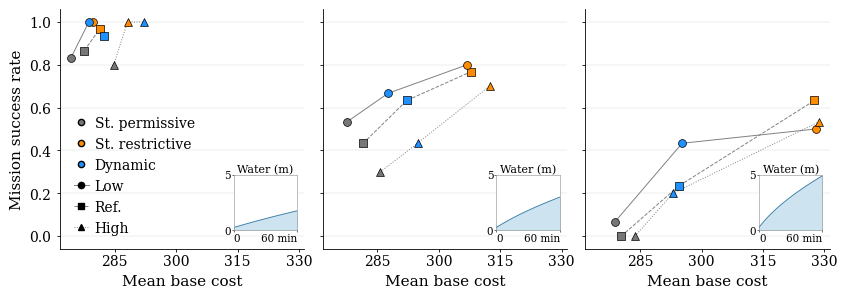


Mission success versus mean base cost
Sensitivity condition: boat_emphasis
Coordinates are the corresponding JSON summary aggregates; costs use illustrative cost units. Lines connect matching departure-rate markers only within each flood scenario.
     Flood scenario Policy strategy Departure rate  Mission success rate (0-1)  Mean base cost  Mission success rate (%)
Slower flood (0.5x)  St. permissive           Ref.                    0.866667      277.547703                 86.666667
Slower flood (0.5x)  St. permissive            Low                    0.833333      274.299701                 83.333333
Slower flood (0.5x)  St. permissive           High                    0.800000      284.725871                 80.000000
Slower flood (0.5x) St. restrictive           Ref.                    0.966667      281.303804                 96.666667
Slower flood (0.5x) St. restrictive            Low                    1.000000      279.592339                100.000000
Slower flood (0.5x) St. r

In [47]:
summary_rows = []
cost_units = set()
for case in flood_order:
    cost_units.add(summaries[case]["experiment"]["cost_model"].get("cost_unit", "cost units"))
    for condition, values in summaries[case]["aggregates"].items():
        parts = condition.split("/")
        if len(parts) != 3:
            continue
        strategy, configuration, sensitivity = parts
        if sensitivity != selected_rescue_sensitivity:
            continue
        summary_rows.append({"flood_case": case, "scenario": strategy,
            "profile_configuration": configuration, "success_rate": values["success_rate"],
            "mean_cost_base": values["mean_cost_base"]})
if len(cost_units) != 1:
    raise ValueError(f"Cost units differ across flood scenarios: {cost_units}")
cost_unit = next(iter(cost_units))
cost_summary = pd.DataFrame(summary_rows)
# Insets summarize water depth across policies and request rates in each case.
water_inset_stats = (
    flood.groupby(["flood_case", "time_minutes"], observed=True)["water_level_m"]
    .mean().rename("mean_water_level_m").reset_index()
)
water_inset_ymax = max(1.0, float(math.ceil(water_inset_stats["mean_water_level_m"].max())))
water_inset_horizon = float(water_inset_stats["time_minutes"].max())
water_inset_rows = []
configuration_line_styles = {"reduced_departure": "-", "baseline": "--", "increased_departure": ":"}
fig, axes = plt.subplots(1, len(flood_order), figsize=(8.4, 2.9), sharex=True, sharey=True)
for ax, case in zip(axes, flood_order):
    case_cost = cost_summary.loc[cost_summary["flood_case"] == case]
    for configuration in configuration_order:
        points = case_cost.loc[case_cost["profile_configuration"] == configuration].sort_values("mean_cost_base")
        ax.plot(points["mean_cost_base"], points["success_rate"], color="0.5",
                linestyle=configuration_line_styles[configuration], linewidth=0.7, zorder=2)
    for _, point in case_cost.iterrows():
        ax.scatter(point["mean_cost_base"], point["success_rate"],
                   marker=configuration_markers[point["profile_configuration"]],
                   color=scenario_colors[point["scenario"]], edgecolor="black", linewidth=0.5, s=32, zorder=3)
    ax.set_xlabel("Mean base cost", fontsize=11)
    ax.set_ylim(-0.06, 1.06)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    format_axis(ax)
    ax.tick_params(axis="both", labelsize=10)
    # Identical inset axes make flood severity comparable across panels.
    water_part = water_inset_stats.loc[
        water_inset_stats["flood_case"] == case,
        ["time_minutes", "mean_water_level_m"],
    ].sort_values("time_minutes")
    initial_level = summaries[case]["experiment"]["simulation_config"]["initial_water_level"]
    water_part = pd.concat([
        pd.DataFrame([{"time_minutes": 0.0, "mean_water_level_m": initial_level}]),
        water_part,
    ], ignore_index=True)
    water_part["flood_case"] = case
    water_inset_rows.extend(water_part.to_dict("records"))
    water_ax = ax.inset_axes([0.71, 0.08, 0.26, 0.23], zorder=5)
    water_ax.set_facecolor("white")
    water_ax.fill_between(water_part["time_minutes"], 0,
                          water_part["mean_water_level_m"], color="#CDE3F0")
    water_ax.plot(water_part["time_minutes"], water_part["mean_water_level_m"],
                  color="#3D7EA6", linewidth=0.65)
    water_ax.set_xlim(0, water_inset_horizon)
    water_ax.set_ylim(0, water_inset_ymax)
    water_ax.set_xticks([0, water_inset_horizon], ["0", f"{water_inset_horizon:g} min"])
    water_ax.set_yticks([0, water_inset_ymax])
    water_ax.set_title("Water (m)", fontsize=8, pad=1)
    water_ax.tick_params(axis="both", labelsize=7.5, pad=0.6, length=1.5, width=0.4)
    water_ax.get_xticklabels()[0].set_ha("left")
    water_ax.get_xticklabels()[-1].set_ha("right")
    for spine in water_ax.spines.values():
        spine.set_color("0.55")
        spine.set_linewidth(0.4)
axes[0].set_ylabel("Mission success rate", fontsize=11)
policy_handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor=scenario_colors[strategy],
                         markeredgecolor="black", markersize=4.5, label=scenario_labels[strategy]) for strategy in scenario_order]
rate_handles = [Line2D([0], [0], marker=configuration_markers[configuration], color="0.5",
                       markerfacecolor="black", markeredgecolor="black",
                       linestyle=configuration_line_styles[configuration], linewidth=0.7,
                       markersize=4.5, label=configuration_labels[configuration]) for configuration in configuration_order]
axes[0].legend(handles=policy_handles + rate_handles, frameon=False,
               loc="lower left", ncol=1, fontsize=10,
               columnspacing=0.4, handlelength=1.1, handletextpad=0.4, borderaxespad=0.6)
fig.tight_layout(pad=0.5)
fig.savefig(plot_dir / "mission_success_vs_mean_base_cost.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()
cost_print = cost_summary.rename(columns={"success_rate": "Mission success rate (0-1)", "mean_cost_base": "Mean base cost"})
cost_print["Mission success rate (%)"] = cost_print["Mission success rate (0-1)"] * 100
print_plot_values("Mission success versus mean base cost", cost_print,
                  f"Coordinates are the corresponding JSON summary aggregates; costs use {cost_unit}. Lines connect matching departure-rate markers only within each flood scenario.")

water_inset_print = pd.DataFrame(water_inset_rows).rename(columns={
    "time_minutes": "Simulation time (min)",
    "mean_water_level_m": "Mean water level (m)",
})
print_plot_values("Water-level area-plot insets", water_inset_print,
                  "Means pool policies and departure-rate conditions within each flood scenario, "
                  "using the selected sensitivity. Time zero is the configured initial water level. "
                  "All insets share time and water-level scales.")


## State transitions by profile and departure rate


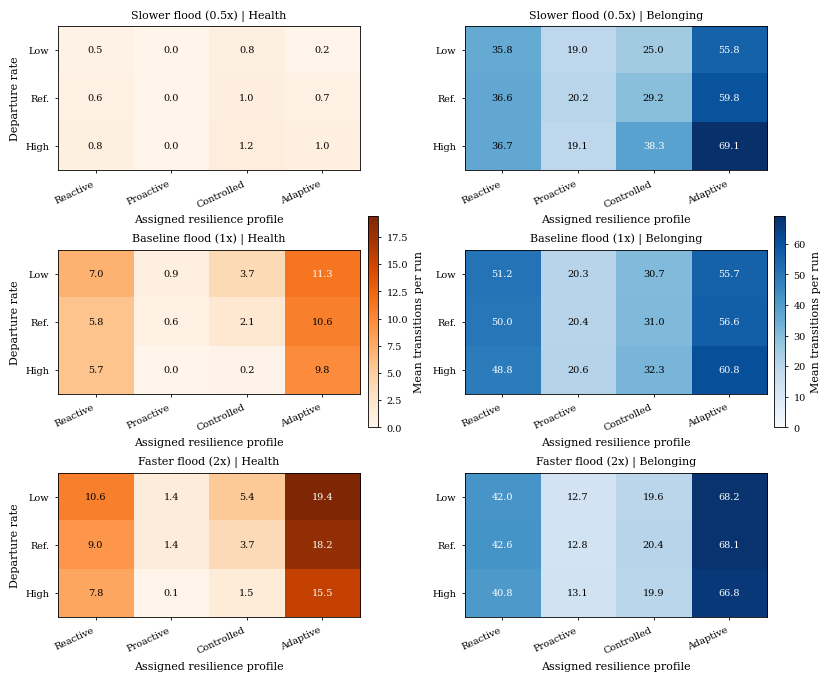


State transitions by profile and departure rate
Sensitivity condition: boat_emphasis
Same profile pooling and zero-filled cells as the original heatmaps; means include runs in which the profile was observed. Color scales are shared across flood scenarios within each region.
     Flood scenario Departure rate Resilience profile    Region  Mean transitions per run
Slower flood (0.5x)            Low           Reactive    Health                  0.450000
Slower flood (0.5x)            Low          Proactive    Health                  0.000000
Slower flood (0.5x)            Low         Controlled    Health                  0.800000
Slower flood (0.5x)            Low           Adaptive    Health                  0.200000
Slower flood (0.5x)           Ref.           Reactive    Health                  0.633333
Slower flood (0.5x)           Ref.          Proactive    Health                  0.000000
Slower flood (0.5x)           Ref.         Controlled    Health                  1.000000
Slow

In [48]:
transition_count_rows = []
for case in flood_order:
    full_summary = read_case_summary(case)
    case_transition_rows = []
    for run in full_summary.get("runs", []):
        if run.get("rescue_sensitivity") != selected_rescue_sensitivity:
            continue
        strategy = run.get("scenario")
        configuration = run.get("profile_configuration")
        if strategy == "low_only":
            observed_profiles = {"Reactive"}
            profile_changes = {}
        elif strategy == "high_only":
            observed_profiles = {"Adaptive"}
            profile_changes = {}
        else:
            profile_changes = {}
            for event in run.get("coordinator_events", []):
                if event.get("event") == "profile_changed":
                    profile_changes.setdefault(event.get("unit"), []).append(
                        (event.get("time", 0), event.get("to", "Reactive"))
                    )
            for changes in profile_changes.values():
                changes.sort(key=lambda item: item[0])
            observed_profiles = {"Reactive"}
            observed_profiles.update(
                profile for changes in profile_changes.values() for _, profile in changes
            )

        counts = {
            (profile, region): 0
            for profile in observed_profiles
            for region in ("Health", "Belonging")
        }
        for unit, transitions in run.get("state_transitions", {}).items():
            changes = profile_changes.get(unit, [])
            for event in transitions:
                before = event.get("from", {})
                after = event.get("to", {})
                event_time = event.get("time", 0)
                if strategy == "low_only":
                    profile = "Reactive"
                elif strategy == "high_only":
                    profile = "Adaptive"
                else:
                    profile = "Reactive"
                    for changed_at, changed_to in changes:
                        if changed_at > event_time:
                            break
                        profile = changed_to
                observed_profiles.add(profile)
                counts.setdefault((profile, "Health"), 0)
                counts.setdefault((profile, "Belonging"), 0)
                if before.get("health") != after.get("health"):
                    counts[(profile, "Health")] += 1
                if before.get("belonging") != after.get("belonging"):
                    counts[(profile, "Belonging")] += 1

        for profile in observed_profiles:
            for region in ("Health", "Belonging"):
                case_transition_rows.append({
                    "profile_configuration": configuration,
                    "profile": profile,
                    "region": region,
                    "transitions_per_run": counts.get((profile, region), 0),
                })
    for item in case_transition_rows:
        item["flood_case"] = case
    transition_count_rows.extend(case_transition_rows)
    del full_summary
transition_counts = pd.DataFrame(transition_count_rows)
transition_summary = (transition_counts.groupby(
    ["flood_case", "profile_configuration", "profile", "region"], observed=True)
    ["transitions_per_run"].mean().reset_index())
profile_order = ["Reactive", "Proactive", "Controlled", "Adaptive"]
transition_cmaps = {"Health": "Oranges", "Belonging": "Blues"}
regions = ("Health", "Belonging")
fig, axes = plt.subplots(len(flood_order), 2, figsize=(8.2, 6.7), constrained_layout=True)
transition_print_rows = []
for column, region in enumerate(regions):
    vmax = max(1.0, float(transition_summary.loc[transition_summary["region"] == region, "transitions_per_run"].max()))
    for row, case in enumerate(flood_order):
        ax = axes[row, column]
        region_stats = transition_summary.loc[(transition_summary["flood_case"] == case)
                                              & (transition_summary["region"] == region)]
        matrix = (region_stats.pivot(index="profile_configuration", columns="profile", values="transitions_per_run")
                  .reindex(index=configuration_order, columns=profile_order).fillna(0))
        values = matrix.to_numpy()
        image = ax.imshow(values, aspect="auto", cmap=transition_cmaps[region], vmin=0, vmax=vmax)
        ax.set_title(f"{flood_labels[case]} | {region}")
        ax.set_xticks(np.arange(len(profile_order)))
        ax.set_xticklabels(profile_order, rotation=25, ha="right")
        ax.set_yticks(np.arange(len(configuration_order)))
        ax.set_yticklabels([configuration_labels[value] for value in configuration_order])
        ax.set_xlabel("Assigned resilience profile")
        if column == 0:
            ax.set_ylabel("Departure rate")
        for r, configuration in enumerate(configuration_order):
            for c, profile in enumerate(profile_order):
                value = values[r, c]
                ax.text(c, r, f"{value:.1f}", ha="center", va="center", fontsize=7,
                        color="white" if value > vmax * 0.55 else "black")
                transition_print_rows.append({"flood_case": case, "profile_configuration": configuration,
                    "Resilience profile": profile, "Region": region, "Mean transitions per run": value})
    fig.colorbar(image, ax=axes[:, column].tolist(), fraction=0.035, pad=0.025, label="Mean transitions per run")
fig.savefig(plot_dir / "state_transitions_by_profile_and_departure_rate.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()
print_plot_values("State transitions by profile and departure rate", pd.DataFrame(transition_print_rows),
                  "Same profile pooling and zero-filled cells as the original heatmaps; means include runs in which the profile was observed. Color scales are shared across flood scenarios within each region.")


## Departure retention


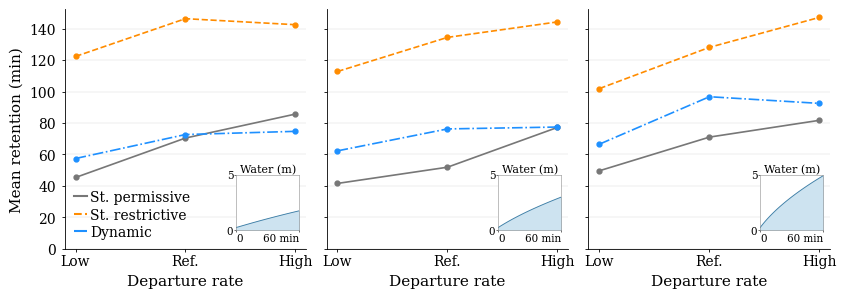


Departure retention
Sensitivity condition: boat_emphasis
Values are retention time in minutes summed across constituents per run, then averaged across runs. Only retention is plotted; attributed retention cost is not a separate panel.
     Flood scenario Policy strategy Departure rate  Mean retention (min)
Baseline flood (1x) St. restrictive           Ref.            134.400000
Baseline flood (1x) St. restrictive           High            144.233333
Baseline flood (1x) St. restrictive            Low            112.733333
Baseline flood (1x)  St. permissive           Ref.             51.900000
Baseline flood (1x)  St. permissive           High             77.166667
Baseline flood (1x)  St. permissive            Low             41.600000
Baseline flood (1x)         Dynamic           Ref.             76.233333
Baseline flood (1x)         Dynamic           High             77.433333
Baseline flood (1x)         Dynamic            Low             62.300000
  Faster flood (2x) St. restrictiv

In [49]:
if "forced_retention_minutes" not in runs.columns:
    raise ValueError("The selected outputs do not contain forced_retention_minutes.")
retention_summary = (runs.groupby(["flood_case", "scenario", "profile_configuration"], observed=True)
                     .agg(forced_retention_minutes=("forced_retention_minutes", "mean")).reset_index())
# Insets summarize water depth across policies and request rates in each case.
water_inset_stats = (
    flood.groupby(["flood_case", "time_minutes"], observed=True)["water_level_m"]
    .mean().rename("mean_water_level_m").reset_index()
)
water_inset_ymax = max(1.0, float(math.ceil(water_inset_stats["mean_water_level_m"].max())))
water_inset_horizon = float(water_inset_stats["time_minutes"].max())
water_inset_rows = []
fig, axes = plt.subplots(1, len(flood_order), figsize=(8.4, 2.9), sharex=True, sharey=True)
for ax, case in zip(axes, flood_order):
    for strategy in scenario_order:
        strategy_data = retention_summary.loc[(retention_summary["flood_case"] == case)
            & (retention_summary["scenario"] == strategy)].set_index("profile_configuration").reindex(configuration_order)
        ax.plot(range(len(configuration_order)), strategy_data["forced_retention_minutes"],
                color=scenario_colors[strategy], linestyle=scenario_line_styles[strategy],
                marker="o", linewidth=1.2, markersize=3.5, label=scenario_labels[strategy])
    ax.set_xticks(range(len(configuration_order)))
    ax.set_xticklabels([configuration_labels[value] for value in configuration_order])
    ax.set_xlabel("Departure rate", fontsize=11)
    format_axis(ax)
    ax.tick_params(axis="both", labelsize=10)
    # Identical inset axes make flood severity comparable across panels.
    water_part = water_inset_stats.loc[
        water_inset_stats["flood_case"] == case,
        ["time_minutes", "mean_water_level_m"],
    ].sort_values("time_minutes")
    initial_level = summaries[case]["experiment"]["simulation_config"]["initial_water_level"]
    water_part = pd.concat([
        pd.DataFrame([{"time_minutes": 0.0, "mean_water_level_m": initial_level}]),
        water_part,
    ], ignore_index=True)
    water_part["flood_case"] = case
    water_inset_rows.extend(water_part.to_dict("records"))
    water_ax = ax.inset_axes([0.71, 0.08, 0.26, 0.23], zorder=5)
    water_ax.set_facecolor("white")
    water_ax.fill_between(water_part["time_minutes"], 0,
                          water_part["mean_water_level_m"], color="#CDE3F0")
    water_ax.plot(water_part["time_minutes"], water_part["mean_water_level_m"],
                  color="#3D7EA6", linewidth=0.65)
    water_ax.set_xlim(0, water_inset_horizon)
    water_ax.set_ylim(0, water_inset_ymax)
    water_ax.set_xticks([0, water_inset_horizon], ["0", f"{water_inset_horizon:g} min"])
    water_ax.set_yticks([0, water_inset_ymax])
    water_ax.set_title("Water (m)", fontsize=8, pad=1)
    water_ax.tick_params(axis="both", labelsize=7.5, pad=0.6, length=1.5, width=0.4)
    water_ax.get_xticklabels()[0].set_ha("left")
    water_ax.get_xticklabels()[-1].set_ha("right")
    for spine in water_ax.spines.values():
        spine.set_color("0.55")
        spine.set_linewidth(0.4)
axes[0].set_ylabel("Mean retention (min)", fontsize=11)
axes[0].set_ylim(bottom=0)
axes[0].legend(handles=strategy_handles, frameon=False, loc="lower left", ncol=1,
               fontsize=10, handletextpad=0.25, labelspacing=0.25,
               columnspacing=0.3, handlelength=0.9, borderaxespad=0.3)
fig.tight_layout(pad=0.5)
fig.savefig(plot_dir / "departure_retention_and_attributed_cost.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()
retention_print = retention_summary.rename(columns={"forced_retention_minutes": "Mean retention (min)"})
print_plot_values("Departure retention", retention_print,
                  "Values are retention time in minutes summed across constituents per run, then averaged across runs. Only retention is plotted; attributed retention cost is not a separate panel.")

water_inset_print = pd.DataFrame(water_inset_rows).rename(columns={
    "time_minutes": "Simulation time (min)",
    "mean_water_level_m": "Mean water level (m)",
})
print_plot_values("Water-level area-plot insets", water_inset_print,
                  "Means pool policies and departure-rate conditions within each flood scenario, "
                  "using the selected sensitivity. Time zero is the configured initial water level. "
                  "All insets share time and water-level scales.")
